### Imports

In [18]:
import os
import torch
import numpy as np
import cv2

from PIL import Image
from tqdm import tqdm

import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms as transforms
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

DATA_DIR = "/Users/arnavkarnik/Desktop/AIBD_Project/Aishwarya thesis"

# 🔥 UPDATED: Include NEGATIVES as class 0
CLASSES = ["NEGATIVES", "PV", "PF", "BP", "EBA", "Vasculitis"]

# 🔥 EXPLICIT mapping (DO NOT rely on enumerate order later)
CLASS_TO_IDX = {
    "NEGATIVES": 0,
    "PV": 1,
    "PF": 2,
    "BP": 3,
    "EBA": 4,
    "Vasculitis": 5
}

NUM_CLASSES = len(CLASSES)

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 20

Using device: cpu


### Augmentations

In [19]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    
    # 🔥 ADD THIS (important for stable training across NEGATIVE vs disease)
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5]),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    
    # 🔥 MUST match train normalization
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5]),
])

### Dataset Class

In [20]:
class AIBDDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform

        for cls in CLASSES:
            cls_path = os.path.join(root_dir, cls)
            if not os.path.exists(cls_path):
                continue

            for img_name in os.listdir(cls_path):
                if img_name.lower().endswith(('.png', '.jpg', '.jpeg', '.tif')):
                    self.samples.append((
                        os.path.join(cls_path, img_name),
                        CLASS_TO_IDX[cls]
                    ))

        print("Total samples:", len(self.samples))

    def __len__(self):
        return len(self.samples)

    def extract_bmz_profile(self, image):
        gray = image.mean(dim=0)
        H = gray.shape[0]

        top = gray[:H//3, :].mean()
        middle = gray[H//3:2*H//3, :].mean()
        bottom = gray[2*H//3:, :].mean()

        return torch.tensor([top, middle, bottom], dtype=torch.float32)

    # 🔥 UPDATED: robust BMZ mask (handles NEGATIVES)
    def extract_bmz_mask(self, image):
        gray = image.mean(dim=0).cpu().numpy()

        grad = np.abs(np.gradient(gray, axis=0))
        grad = cv2.GaussianBlur(grad, (9, 9), 0)

        # 🔥 FIX: if gradient is too weak → no BMZ signal (NEGATIVE case)
        if np.max(grad) < 0.05:
            mask = np.zeros_like(gray)
            return torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        bmz_line = np.argmax(grad, axis=0)

        mask = np.zeros_like(gray)

        for x in range(len(bmz_line)):
            y = bmz_line[x]

            y1 = max(0, y - 4)
            y2 = min(mask.shape[0], y + 4)

            mask[y1:y2, x] = 1

        mask = torch.tensor(mask, dtype=torch.float32)
        return mask.unsqueeze(0)

    # 🔥 UPDATED: stable distance map
    def compute_distance_map(self, bmz_mask):
        mask = bmz_mask.squeeze(0).cpu().numpy()

        # 🔥 FIX: if mask is empty (NEGATIVE case)
        if np.sum(mask) < 10:
            return torch.zeros_like(bmz_mask)

        dist_out = cv2.distanceTransform((1 - mask).astype(np.uint8), cv2.DIST_L2, 5)
        dist_in = cv2.distanceTransform(mask.astype(np.uint8), cv2.DIST_L2, 5)

        signed_dist = dist_out - dist_in

        signed_dist = signed_dist / (np.max(np.abs(signed_dist)) + 1e-6)

        return torch.tensor(signed_dist, dtype=torch.float32).unsqueeze(0)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        profile = self.extract_bmz_profile(image)
        bmz_mask = self.extract_bmz_mask(image)
        distance_map = self.compute_distance_map(bmz_mask)

        return {
            "image": image,
            "bmz_mask": bmz_mask,
            "distance_map": distance_map,
            "profile": profile,
            "label": torch.tensor(label, dtype=torch.long)
        }

### Dataset Distribution

In [21]:
dataset = AIBDDataset(DATA_DIR, transform=None)  # 🔥 NO transform here

indices = list(range(len(dataset)))
labels = [dataset.samples[i][1] for i in indices]

# 🔥 DEBUG: class distribution check (VERY IMPORTANT NOW)
from collections import Counter
print("Full dataset distribution:", Counter(labels))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    stratify=labels,
    random_state=42
)

# 🔥 Apply transforms AFTER split
train_dataset = Subset(AIBDDataset(DATA_DIR, transform=train_transform), train_idx)
val_dataset = Subset(AIBDDataset(DATA_DIR, transform=val_transform), val_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train:", len(train_dataset), "Val:", len(val_dataset))

Total samples: 7883
Full dataset distribution: Counter({3: 2937, 1: 2719, 5: 1488, 0: 378, 4: 197, 2: 164})
Total samples: 7883
Total samples: 7883
Train: 6306 Val: 1577


### BMZ Attention

In [22]:
class BMZAttention(nn.Module):
    def __init__(self, in_channels=512):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Conv2d(in_channels, 256, 1),
            nn.ReLU(),
            nn.Conv2d(256, 1, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        attn = self.attention(x)

        # 🔥 NEW: clamp attention (prevents spikes on noisy NEGATIVE samples)
        attn = torch.clamp(attn, 0.0, 1.0)

        # 🔥 STABILITY: controlled amplification
        out = x * (1 + 0.8 * attn)

        return out, attn

### Image Encoder

In [23]:
class ImageEncoder(nn.Module):
    def __init__(self, out_dim=256):
        super().__init__()

        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

        # 🔥 CHANGE: 3 → 4 input channels
        backbone.conv1 = nn.Conv2d(
            4, 64, kernel_size=7, stride=2, padding=3, bias=False
        )

        self.features = nn.Sequential(*list(backbone.children())[:-2])
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.attn = BMZAttention(512)

        self.projection = nn.Sequential(
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, out_dim)
        )

    def forward(self, x, bmz_mask, distance_map):
        # 🔥 Ensure distance_map is safe (NEGATIVE stability)
        distance_map = torch.clamp(distance_map, -1.0, 1.0)

        # 🔥 ADD distance channel
        x = torch.cat([x, distance_map], dim=1)

        feat_map = self.features(x)

        bmz_mask = nn.functional.interpolate(
            bmz_mask,
            size=feat_map.shape[-2:],
            mode='bilinear',
            align_corners=False
        )

        # 🔥 NEW: prevent BMZ amplification on empty masks (NEGATIVE case)
        bmz_strength = torch.mean(bmz_mask, dim=[1,2,3], keepdim=True)
        bmz_gate = (bmz_strength > 0.01).float()

        feat_map = feat_map * (1 + 0.8 * bmz_mask * bmz_gate)

        feat_map, attn = self.attn(feat_map)

        pooled = self.pool(feat_map).view(x.size(0), -1)
        out = self.projection(pooled)

        return out, attn

### BMZ Profile Encoder

In [24]:
class BMZProfileEncoder(nn.Module):
    def __init__(self, input_dim=3, out_dim=64):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),

            # 🔥 UPDATED: more stable for small/imbalanced batches
            nn.BatchNorm1d(32, eps=1e-5, momentum=0.1),

            nn.Linear(32, out_dim)
        )

    def forward(self, x):
        return self.net(x)

### Prototype Layer

In [25]:
class PrototypeLayer(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, feat_dim=320):
        super().__init__()

        self.prototypes = nn.Parameter(torch.randn(num_classes, feat_dim))

        # 🔥 IMPORTANT: initialize properly (helps rare classes like PF/EBA)
        nn.init.kaiming_normal_(self.prototypes, nonlinearity='linear')

        self.scale = nn.Parameter(torch.tensor(10.0))

    def forward(self, features):
        features = nn.functional.normalize(features, dim=1)
        prototypes = nn.functional.normalize(self.prototypes, dim=1)

        logits = torch.matmul(features, prototypes.T)

        return logits * self.scale

### BPCL Model

In [26]:
class BCPLModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.image_encoder = ImageEncoder(256)
        self.profile_encoder = BMZProfileEncoder(3, 64)

        # 🔥 FIX: use NUM_CLASSES (ensures consistency everywhere)
        self.prototype_layer = PrototypeLayer(NUM_CLASSES, 320)

    def forward(self, image, bmz_mask, distance_map, profile):
        f_img, attn = self.image_encoder(image, bmz_mask, distance_map)
        f_prof = self.profile_encoder(profile)

        # 🔥 normalization (important for prototype stability)
        f_img = nn.functional.normalize(f_img, dim=1)
        f_prof = nn.functional.normalize(f_prof, dim=1)

        fused = torch.cat([f_img, f_prof], dim=1)

        # 🔥 NEW: normalize fused embedding (helps rare classes + NEGATIVE)
        fused = nn.functional.normalize(fused, dim=1)

        logits = self.prototype_layer(fused)

        return logits, fused, attn

### Weights and Loss Functions

In [27]:
labels_all = [dataset.samples[i][1] for i in range(len(dataset))]
class_counts = np.bincount(labels_all, minlength=NUM_CLASSES)

# 🔥 FIX 1: smoother inverse frequency (prevents extreme weights)
weights = 1.0 / (class_counts + 1e-6)
weights = weights / weights.sum() * NUM_CLASSES  # normalize

# 🔥 FIX 2: controlled boosting for hard classes
weights[CLASS_TO_IDX["PF"]] *= 1.5
weights[CLASS_TO_IDX["EBA"]] *= 1.3

# 🔥 FIX 3: ensure NEGATIVE is not ignored
weights[CLASS_TO_IDX["NEGATIVES"]] *= 1.2

weights = torch.tensor(weights, dtype=torch.float32).to(DEVICE)

print("Class counts:", class_counts)
print("Class weights:", weights)


# 🔥 FOCAL LOSS (stable)
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, weight=self.alpha, reduction='none')
        pt = torch.exp(-ce_loss)
        loss = ((1 - pt) ** self.gamma) * ce_loss
        return loss.mean()


ce_loss_fn = FocalLoss(alpha=weights, gamma=2)


def prototype_loss(features, labels, prototypes):
    proto = prototypes[labels]
    return ((features - proto) ** 2).sum(dim=1).mean()


# 🔥 UPDATED: attention loss safer for NEGATIVES
def attention_loss(attn):
    sparsity = attn.mean()
    sharpness = (attn * (1 - attn)).mean()

    # 🔥 reduce penalty slightly (NEGATIVE images naturally flat)
    return 0.7 * sparsity + 0.3 * sharpness


def compute_loss(logits, features, labels, model, attn):
    ce = ce_loss_fn(logits, labels)

    proto = prototype_loss(
        features,
        labels,
        model.prototype_layer.prototypes
    )

    attn_l = attention_loss(attn)

    # 🔥 FINAL BALANCE (important)
    total = ce + 0.2 * proto + 0.1 * attn_l

    return total, ce, proto, attn_l

Class counts: [ 378 2719  164 2937  197 1488]
Class weights: tensor([1.2532, 0.1452, 3.6105, 0.1344, 2.6049, 0.2653])


### Training Loop and Evaluation Loop

In [28]:
model = BCPLModel().to(DEVICE)

optimizer = optim.Adam(model.parameters(), lr=1e-4)

best_val_acc = 0
patience = 6
counter = 0


# 🔥 NEW: binary evaluation (VERY IMPORTANT FOR PAPER)
def evaluate_binary(loader):
    model.eval()
    preds_all, labels_all = [], []

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(DEVICE)
            bmz_mask = batch["bmz_mask"].to(DEVICE)
            distance_map = batch["distance_map"].to(DEVICE)
            profile = batch["profile"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            logits, _, _ = model(images, bmz_mask, distance_map, profile)
            preds = torch.argmax(logits, dim=1)

            # 🔥 convert to binary: 0 = NEGATIVE, 1 = DISEASE
            preds_bin = (preds != 0).long()
            labels_bin = (labels != 0).long()

            preds_all.extend(preds_bin.cpu().numpy())
            labels_all.extend(labels_bin.cpu().numpy())

    return accuracy_score(labels_all, preds_all)


def evaluate(loader):
    model.eval()
    preds_all, labels_all = [], []

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(DEVICE)
            bmz_mask = batch["bmz_mask"].to(DEVICE)
            distance_map = batch["distance_map"].to(DEVICE)
            profile = batch["profile"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            logits, _, _ = model(images, bmz_mask, distance_map, profile)
            preds = torch.argmax(logits, dim=1)

            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())

    return accuracy_score(labels_all, preds_all)


from sklearn.metrics import classification_report

def evaluate_detailed(loader):
    model.eval()
    preds_all, labels_all = [], []

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(DEVICE)
            bmz_mask = batch["bmz_mask"].to(DEVICE)
            distance_map = batch["distance_map"].to(DEVICE)
            profile = batch["profile"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            logits, _, _ = model(images, bmz_mask, distance_map, profile)
            preds = torch.argmax(logits, dim=1)

            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())

    print("\n📊 Classification Report:\n")
    print(classification_report(labels_all, preds_all, target_names=CLASSES))


for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images = batch["image"].to(DEVICE)
        bmz_mask = batch["bmz_mask"].to(DEVICE)
        distance_map = batch["distance_map"].to(DEVICE)
        profile = batch["profile"].to(DEVICE)
        labels = batch["label"].to(DEVICE)

        optimizer.zero_grad()

        logits, features, attn = model(images, bmz_mask, distance_map, profile)

        loss, ce, proto, attn_l = compute_loss(
            logits, features, labels, model, attn
        )

        loss.backward()

        # 🔥 Stability
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()

        total_loss += loss.item()

    train_acc = evaluate(train_loader)
    val_acc = evaluate(val_loader)

    # 🔥 NEW: binary accuracy
    val_bin_acc = evaluate_binary(val_loader)

    print(f"\nEpoch {epoch+1}")
    print(f"Loss: {total_loss/len(train_loader):.4f}")
    print(f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")
    print(f"Binary (Disease vs Negative) Acc: {val_bin_acc:.4f}")

    # 🔥 Early stopping
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model_bmz_distance.pth")
        print("✅ Saved Best Model")
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("⛔ Early stopping triggered")
        break


# 🔥 FINAL REPORT
evaluate_detailed(val_loader)

Epoch 1/20: 100%|██████████| 395/395 [06:30<00:00,  1.01it/s]



Epoch 1
Loss: 0.4642
Train Acc: 0.4921 | Val Acc: 0.5124
Binary (Disease vs Negative) Acc: 0.8326
✅ Saved Best Model


Epoch 2/20: 100%|██████████| 395/395 [06:26<00:00,  1.02it/s]



Epoch 2
Loss: 0.2911
Train Acc: 0.5181 | Val Acc: 0.5263
Binary (Disease vs Negative) Acc: 0.9791
✅ Saved Best Model


Epoch 3/20: 100%|██████████| 395/395 [06:34<00:00,  1.00it/s]



Epoch 3
Loss: 0.2354
Train Acc: 0.5350 | Val Acc: 0.5117
Binary (Disease vs Negative) Acc: 0.8668


... (28 outputs left out)

Epoch 18/20: 100%|██████████| 395/395 [12:42<00:00,  1.93s/it]



Epoch 18
Loss: 0.0347
Train Acc: 0.8555 | Val Acc: 0.7971
Binary (Disease vs Negative) Acc: 0.9867


Epoch 19/20: 100%|██████████| 395/395 [07:44<00:00,  1.18s/it]



Epoch 19
Loss: 0.0370
Train Acc: 0.7690 | Val Acc: 0.7413
Binary (Disease vs Negative) Acc: 0.9011
⛔ Early stopping triggered

📊 Classification Report:

              precision    recall  f1-score   support

   NEGATIVES       0.32      0.97      0.49        76
          PV       0.87      0.72      0.79       544
          PF       0.16      0.58      0.26        33
          BP       0.92      0.77      0.84       587
         EBA       0.41      0.28      0.33        39
  Vasculitis       0.84      0.75      0.79       298

    accuracy                           0.74      1577
   macro avg       0.59      0.68      0.58      1577
weighted avg       0.83      0.74      0.77      1577



### Confusion Matrix

In [31]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

def plot_confusion_matrix(loader, model, normalize=False):
    model.eval()
    preds_all, labels_all = [], []

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(DEVICE)
            bmz_mask = batch["bmz_mask"].to(DEVICE)
            distance_map = batch["distance_map"].to(DEVICE)
            profile = batch["profile"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            logits, _, _ = model(images, bmz_mask, distance_map, profile)
            preds = torch.argmax(logits, dim=1)

            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())

    cm = confusion_matrix(labels_all, preds_all)

    if normalize:
        cm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-6)

    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt=".2f" if normalize else "d",
                xticklabels=CLASSES,
                yticklabels=CLASSES,
                cmap="Blues")

    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix" + (" (Normalized)" if normalize else ""))
    plt.tight_layout()
    plt.show()

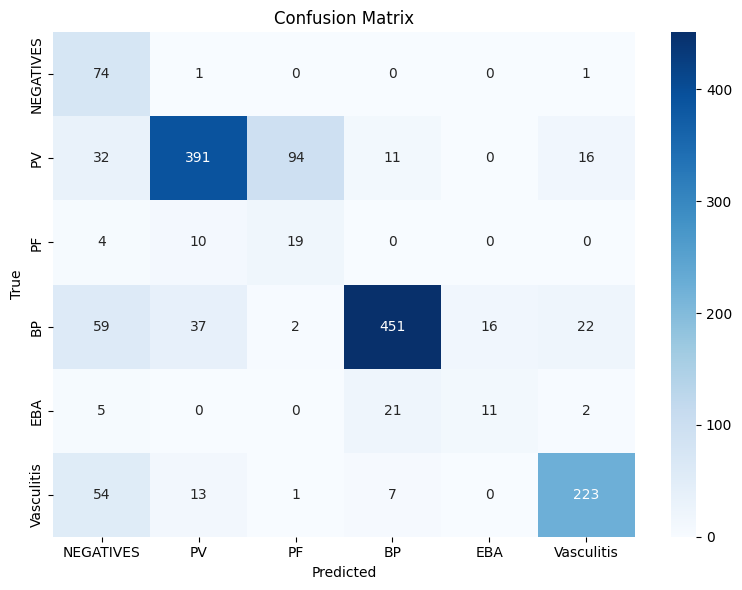

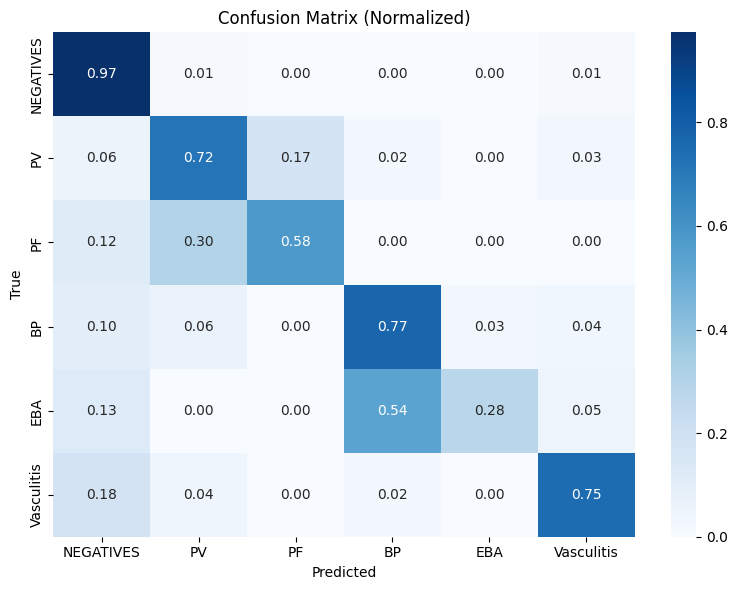

In [32]:
plot_confusion_matrix(val_loader, model, normalize=False)
plot_confusion_matrix(val_loader, model, normalize=True)

### Class Distribution

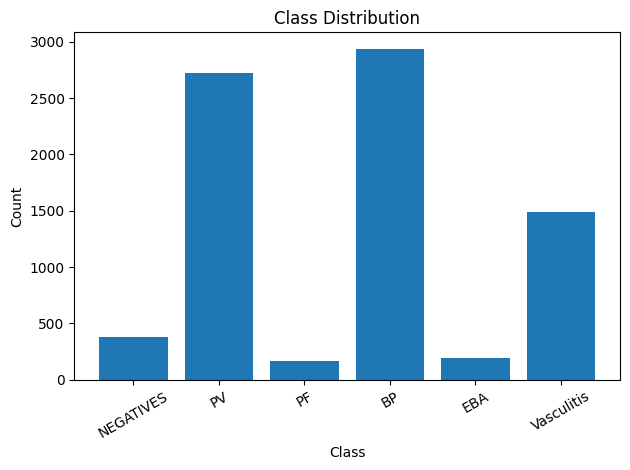

In [33]:
from collections import Counter

def plot_class_distribution(labels):
    count = Counter(labels)

    classes = [CLASSES[i] for i in count.keys()]
    values = list(count.values())

    plt.figure()
    plt.bar(classes, values)
    plt.title("Class Distribution")
    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

plot_class_distribution(labels_all)

### Class Wise Metrics

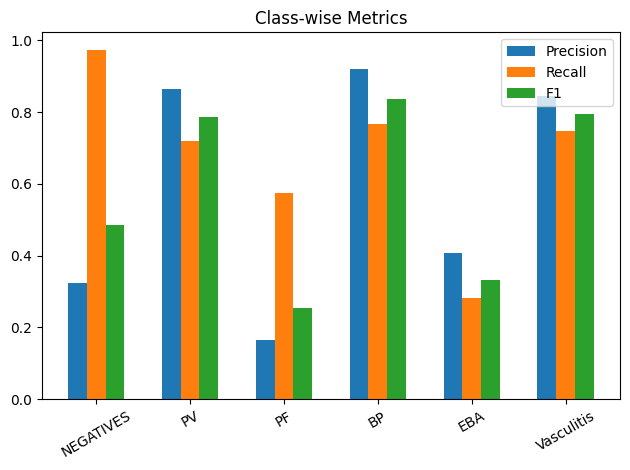

In [35]:
from sklearn.metrics import precision_recall_fscore_support

def plot_metrics(loader, model):
    model.eval()
    preds_all, labels_all = [], []

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(DEVICE)
            bmz_mask = batch["bmz_mask"].to(DEVICE)
            distance_map = batch["distance_map"].to(DEVICE)
            profile = batch["profile"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            logits, _, _ = model(images, bmz_mask, distance_map, profile)
            preds = torch.argmax(logits, dim=1)

            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels_all, preds_all, average=None
    )

    x = np.arange(len(CLASSES))

    plt.figure()
    plt.bar(x - 0.2, precision, width=0.2, label="Precision")
    plt.bar(x, recall, width=0.2, label="Recall")
    plt.bar(x + 0.2, f1, width=0.2, label="F1")

    plt.xticks(x, CLASSES, rotation=30)
    plt.title("Class-wise Metrics")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_metrics(val_loader, model)

### Prototype Similarity Matrix

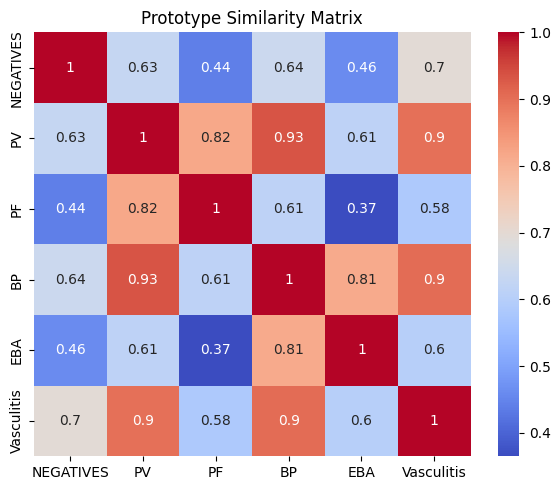

In [36]:
import torch
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def plot_prototype_similarity(model):
    proto = model.prototype_layer.prototypes.detach().cpu()

    proto = torch.nn.functional.normalize(proto, dim=1)
    sim = torch.matmul(proto, proto.T).numpy()

    plt.figure(figsize=(6,5))
    sns.heatmap(sim, annot=True, xticklabels=CLASSES, yticklabels=CLASSES, cmap="coolwarm")
    plt.title("Prototype Similarity Matrix")
    plt.tight_layout()
    plt.show()

plot_prototype_similarity(model)

### TNSE

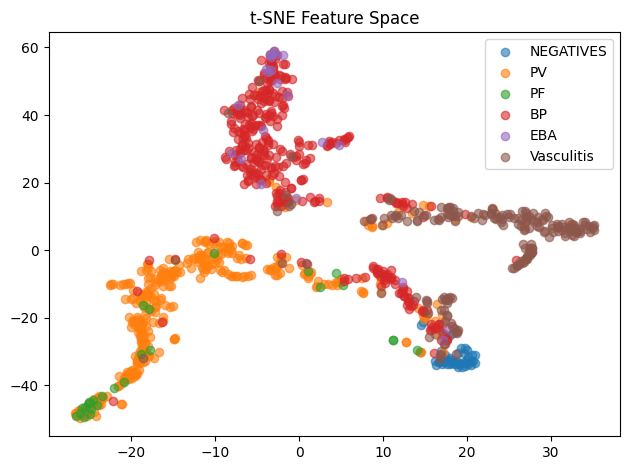

In [37]:
from sklearn.manifold import TSNE

def plot_tsne(loader, model, max_samples=1000):
    model.eval()
    features_all, labels_all = [], []

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(DEVICE)
            bmz_mask = batch["bmz_mask"].to(DEVICE)
            distance_map = batch["distance_map"].to(DEVICE)
            profile = batch["profile"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            _, features, _ = model(images, bmz_mask, distance_map, profile)

            features_all.append(features.cpu())
            labels_all.extend(labels.cpu().numpy())

            if len(labels_all) > max_samples:
                break

    features_all = torch.cat(features_all).numpy()
    labels_all = np.array(labels_all[:len(features_all)])

    tsne = TSNE(n_components=2, perplexity=30)
    reduced = tsne.fit_transform(features_all)

    plt.figure()
    for i, cls in enumerate(CLASSES):
        idx = labels_all == i
        plt.scatter(reduced[idx, 0], reduced[idx, 1], label=cls, alpha=0.6)

    plt.legend()
    plt.title("t-SNE Feature Space")
    plt.tight_layout()
    plt.show()

plot_tsne(val_loader, model)

### BMZ Attention Overlay

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.7490196].


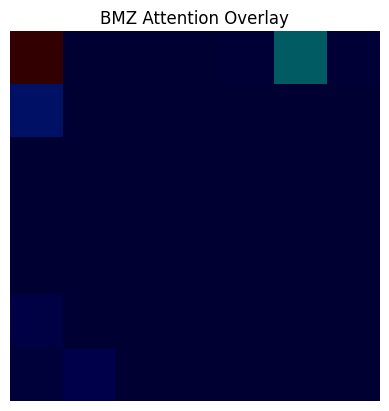

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


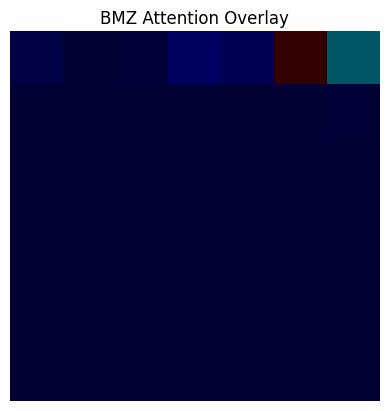

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.8901961].


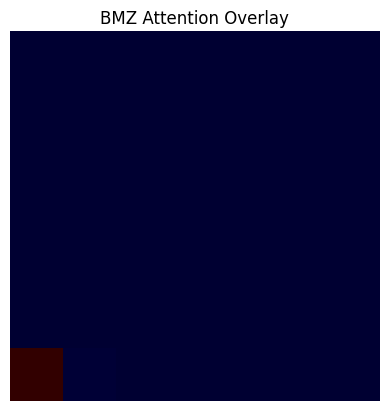

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.99215686..0.99215686].


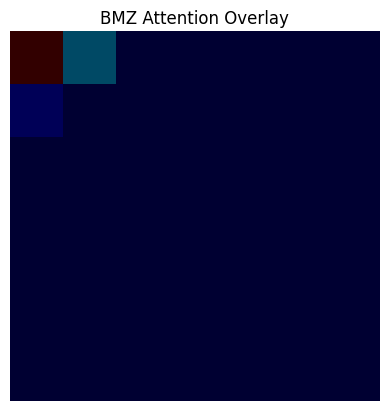

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.92941177].


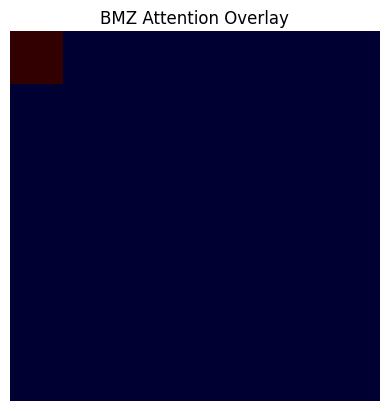

In [38]:
import matplotlib.pyplot as plt

def visualize_attention(loader, model, num_samples=5):
    model.eval()

    count = 0
    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(DEVICE)
            bmz_mask = batch["bmz_mask"].to(DEVICE)
            distance_map = batch["distance_map"].to(DEVICE)
            profile = batch["profile"].to(DEVICE)

            logits, _, attn = model(images, bmz_mask, distance_map, profile)

            for i in range(images.size(0)):
                img = images[i].cpu().permute(1,2,0).numpy()
                attention = attn[i].cpu().squeeze().numpy()

                plt.figure()
                plt.imshow(img)
                plt.imshow(attention, cmap='jet', alpha=0.4)
                plt.title("BMZ Attention Overlay")
                plt.axis('off')
                plt.show()

                count += 1
                if count >= num_samples:
                    return

visualize_attention(val_loader, model)

### Distance Map

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.7490196].


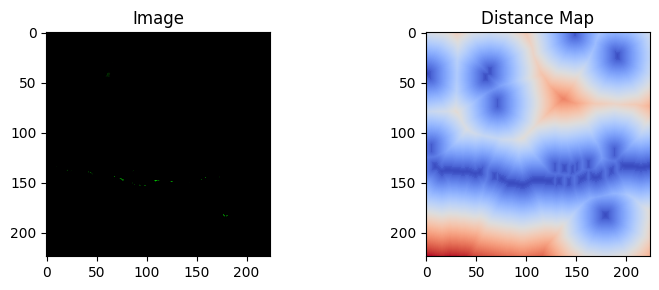

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


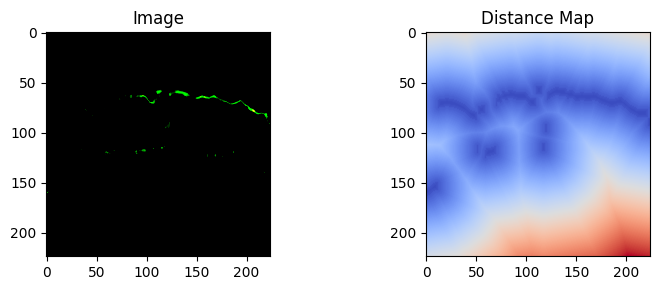

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.8901961].


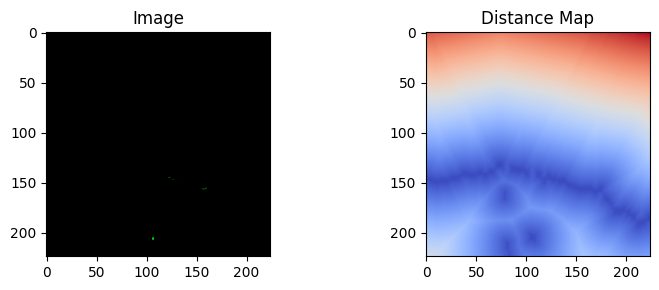

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.99215686..0.99215686].


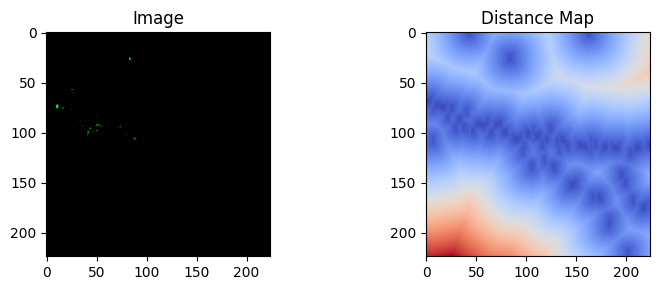

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.92941177].


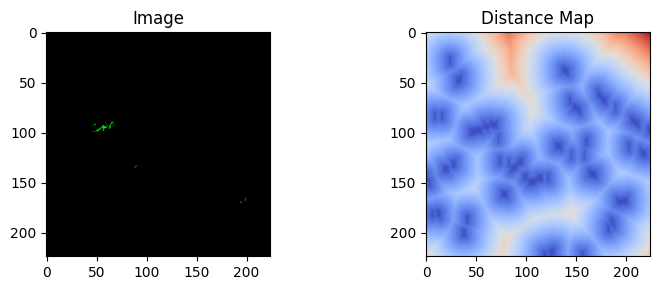

In [39]:
def visualize_distance_map(loader, num_samples=5):
    count = 0
    for batch in loader:
        images = batch["image"]
        dist = batch["distance_map"]

        for i in range(images.size(0)):
            img = images[i].permute(1,2,0).numpy()
            dmap = dist[i].squeeze().numpy()

            plt.figure(figsize=(8,3))

            plt.subplot(1,2,1)
            plt.imshow(img)
            plt.title("Image")

            plt.subplot(1,2,2)
            plt.imshow(dmap, cmap='coolwarm')
            plt.title("Distance Map")

            plt.tight_layout()
            plt.show()

            count += 1
            if count >= num_samples:
                return

visualize_distance_map(val_loader)

### Prediction Confidence Distribution

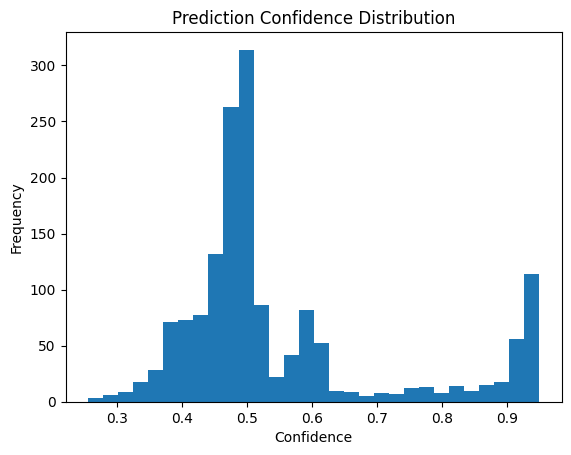

In [40]:
def plot_confidence_distribution(loader, model):
    model.eval()
    confidences = []
    labels_all = []

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(DEVICE)
            bmz_mask = batch["bmz_mask"].to(DEVICE)
            distance_map = batch["distance_map"].to(DEVICE)
            profile = batch["profile"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            logits, _, _ = model(images, bmz_mask, distance_map, profile)
            probs = torch.softmax(logits, dim=1)

            conf, _ = torch.max(probs, dim=1)

            confidences.extend(conf.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())

    plt.figure()
    plt.hist(confidences, bins=30)
    plt.title("Prediction Confidence Distribution")
    plt.xlabel("Confidence")
    plt.ylabel("Frequency")
    plt.show()

plot_confidence_distribution(val_loader, model)

### Misclassification

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


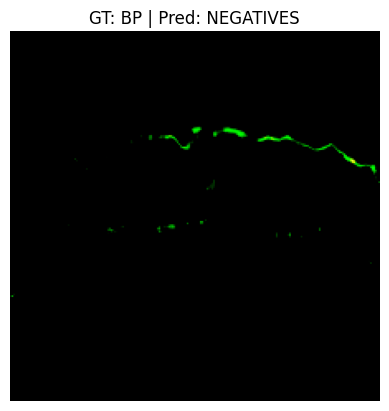

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.92941177].


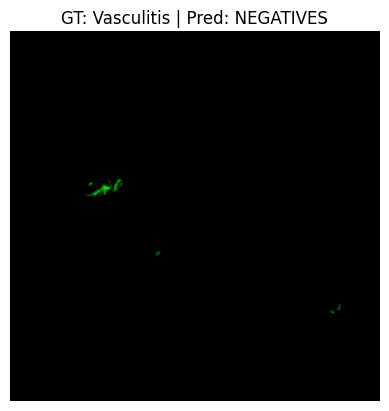

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.73333335].


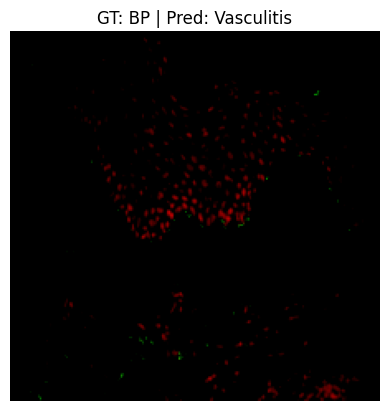

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.24705887].


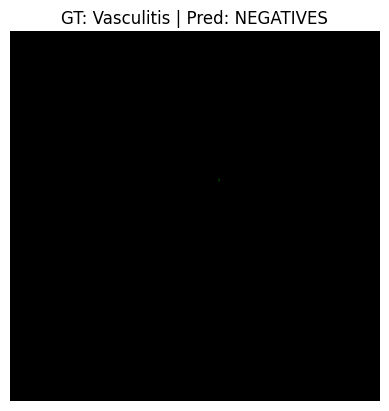

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


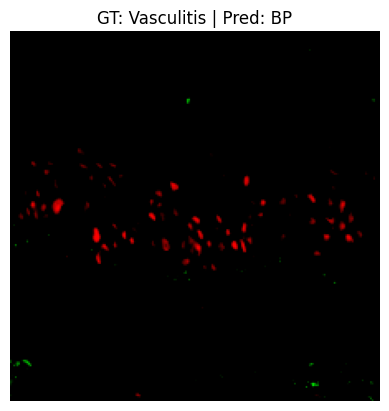

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.6627451].


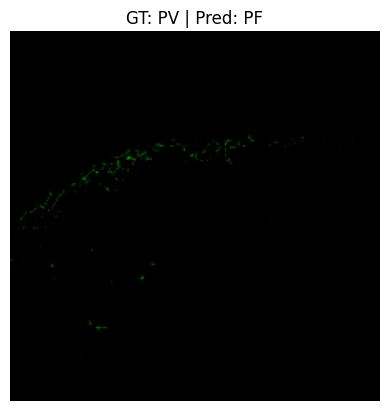

In [41]:
def show_misclassifications(loader, model, num_samples=6):
    model.eval()
    count = 0

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(DEVICE)
            bmz_mask = batch["bmz_mask"].to(DEVICE)
            distance_map = batch["distance_map"].to(DEVICE)
            profile = batch["profile"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            logits, _, _ = model(images, bmz_mask, distance_map, profile)
            preds = torch.argmax(logits, dim=1)

            for i in range(images.size(0)):
                if preds[i] != labels[i]:
                    img = images[i].cpu().permute(1,2,0).numpy()

                    plt.figure()
                    plt.imshow(img)
                    plt.title(f"GT: {CLASSES[labels[i]]} | Pred: {CLASSES[preds[i]]}")
                    plt.axis('off')
                    plt.show()

                    count += 1
                    if count >= num_samples:
                        return

show_misclassifications(val_loader, model)